# Experiment 5 — Pretrained Vision Transformer on Colab

This notebook fine-tunes an ImageNet-pretrained ViT-B/16. It warms up the classification
head and then unfreezes only the final two encoder blocks. Training a transformer from
scratch is intentionally avoided.

## 1. Configuration

In [1]:
import json
import random
import shutil
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm import tqdm

IN_COLAB                 = 'google.colab' in sys.modules
RANDOM_STATE             = 42
BATCH_SIZE               = 16
NUM_WORKERS              = 2 if IN_COLAB else 8
EXPECTED_VALIDATION_ROWS = 16_984

HEAD_EPOCHS              = 1
ENCODER_EPOCHS           = 4
HEAD_LEARNING_RATE       = 5e-4
ENCODER_LEARNING_RATE    = 2e-5
WEIGHT_DECAY             = 5e-2
LABEL_SMOOTHING          = 0.10
EARLY_STOPPING_PATIENCE  = 2

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    DRIVE_DIR            = Path('/content/drive/MyDrive/rakuten_colab')
    IMAGE_ZIP_PATH       = DRIVE_DIR / 'image_train.zip'
    MANIFEST_DRIVE_PATH  = DRIVE_DIR / 'image_split_clean.csv'
    OUTPUT_DIR           = DRIVE_DIR / 'outputs'

    LOCAL_DIR            = Path('/content/rakuten_experiment')
    LOCAL_IMAGE_DIR      = LOCAL_DIR / 'images'
    LOCAL_MANIFEST_PATH  = LOCAL_DIR / 'image_split_clean.csv'
else:
    PROJECT_ROOT         = Path.cwd().resolve()
    while PROJECT_ROOT.name in {'03_image_fineTuning', 'notebooks'}:
        PROJECT_ROOT = PROJECT_ROOT.parent

    LOCAL_IMAGE_DIR      = PROJECT_ROOT / 'data' / 'raw' / 'images' / 'image_train'
    LOCAL_MANIFEST_PATH  = PROJECT_ROOT / 'data' / 'processed' / 'image_split_clean.csv'
    OUTPUT_DIR           = PROJECT_ROOT / 'models' / 'outputs'

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('No GPU found. Make sure CUDA is available.')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Mode   :', 'Colab' if IN_COLAB else 'Local')
print('Device :', torch.cuda.get_device_name(0))
print('Outputs:', OUTPUT_DIR)

/home/bquehl/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-ehp_gnrq because there was an issue with the default path (/home/bquehl/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Mode   : Local
Device : NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU
Outputs: /home/bquehl/Development/Rakuten2/Rakuten2/liora-capstone/models/outputs


## 2. Stage images and verify the shared split

In [2]:
if IN_COLAB:
    assert IMAGE_ZIP_PATH.exists(), f'Missing private image archive: {IMAGE_ZIP_PATH}'
    assert MANIFEST_DRIVE_PATH.exists(), f'Missing split manifest: {MANIFEST_DRIVE_PATH}'

    LOCAL_DIR.mkdir(parents=True, exist_ok=True)
    LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
    shutil.copy2(MANIFEST_DRIVE_PATH, LOCAL_MANIFEST_PATH)

    if not any(LOCAL_IMAGE_DIR.rglob('*.jpg')):
        local_zip_path = LOCAL_DIR / IMAGE_ZIP_PATH.name
        shutil.copy2(IMAGE_ZIP_PATH, local_zip_path)
        with zipfile.ZipFile(local_zip_path) as archive:
            archive.extractall(LOCAL_IMAGE_DIR)
        local_zip_path.unlink()
else:
    assert LOCAL_IMAGE_DIR.exists(), f'Missing image directory: {LOCAL_IMAGE_DIR}'
    assert LOCAL_MANIFEST_PATH.exists(), f'Missing split manifest: {LOCAL_MANIFEST_PATH}'

image_paths      = list(LOCAL_IMAGE_DIR.rglob('*.jpg'))
filename_to_path = {path.name: path for path in image_paths}

if len(filename_to_path) != len(image_paths):
    raise ValueError('Duplicate image filenames were found inside the image directory.')

manifest            = pd.read_csv(LOCAL_MANIFEST_PATH)
required_columns    = {'row_id', 'imageid', 'productid', 'prdtypecode', 'split'}
assert required_columns.issubset(manifest.columns)
assert manifest['row_id'].is_unique
assert set(manifest['split']) == {'train', 'validation'}

# Validation must remain identical for image, text and fusion experiments.
validation_rows     = int(manifest['split'].eq('validation').sum())
assert validation_rows == EXPECTED_VALIDATION_ROWS, (
    f'Validation contains {validation_rows:,} rows instead of {EXPECTED_VALIDATION_ROWS:,}.'
)

class_codes         = sorted(manifest['prdtypecode'].astype(int).unique().tolist())
assert len(class_codes) == 27
class_to_index      = {code: index for index, code in enumerate(class_codes)}
index_to_class      = {index: code for code, index in class_to_index.items()}
manifest['target']  = manifest['prdtypecode'].astype(int).map(class_to_index)

expected_names = [
    f'image_{int(row.imageid)}_product_{int(row.productid)}.jpg'
    for row in manifest.itertuples(index=False)
]

manifest['image_path']  = [filename_to_path.get(name) for name in expected_names]
missing_mask            = manifest['image_path'].isna()

if missing_mask.any():
    examples = [expected_names[i] for i in np.flatnonzero(missing_mask.to_numpy())[:5]]
    raise FileNotFoundError(f'{missing_mask.sum():,} images are missing. Examples: {examples}')

train_manifest          = manifest.loc[manifest['split'].eq('train')].reset_index(drop=True)
validation_manifest     = manifest.loc[manifest['split'].eq('validation')].reset_index(drop=True)

display(pd.DataFrame({
    'rows': [len(train_manifest), len(validation_manifest)],
    'classes': [train_manifest['target'].nunique(), validation_manifest['target'].nunique()],
}, index=['train', 'validation']))

,rows,classes
train,62312,27
validation,16984,27


## 3. Build ViT-compatible datasets

In [3]:
from torchvision.models import ViT_B_16_Weights, vit_b_16

weights = ViT_B_16_Weights.IMAGENET1K_V1
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.80, 1.00)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
validation_transform = weights.transforms()

class RakutenImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row['image_path']) as image:
            image_tensor = self.transform(image.convert('RGB'))
        return image_tensor, int(row['target']), int(row['row_id'])


def make_loaders(train_transform, validation_transform, batch_size=BATCH_SIZE):
    train_dataset = RakutenImageDataset(train_manifest, train_transform)
    validation_dataset = RakutenImageDataset(validation_manifest, validation_transform)
    options = {
        'batch_size'        : batch_size,
        'num_workers'       : NUM_WORKERS,
        'pin_memory'        : True,
        'persistent_workers': NUM_WORKERS > 0,
    }
    generator = torch.Generator().manual_seed(RANDOM_STATE)
    train_loader = DataLoader(
        train_dataset, shuffle=True, generator=generator, **options
    )
    validation_loader = DataLoader(
        validation_dataset, shuffle=False, **options
    )
    return train_loader, validation_loader


@torch.no_grad()
def evaluate(model, loader, criterion, return_probabilities=False):
    model.eval()
    loss_total  = 0.0
    row_count   = 0
    targets_all, predictions_all, row_ids_all, probabilities_all = [], [], [], []

    for images, targets, row_ids in tqdm(loader, desc='Validation'):
        images  = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits  = model(images)
            loss    = criterion(logits, targets)

        probabilities   = torch.softmax(logits.float(), dim=1)
        predictions     = probabilities.argmax(dim=1)
        batch_size      = targets.size(0)
        loss_total     += loss.item() * batch_size
        row_count      += batch_size
        targets_all.extend(targets.cpu().tolist())
        predictions_all.extend(predictions.cpu().tolist())
        row_ids_all.extend(row_ids.tolist())

        if return_probabilities:
            probabilities_all.append(probabilities.cpu().numpy())

    y_true = np.asarray(targets_all)
    y_pred = np.asarray(predictions_all)
    result = {
        'validation_loss'   : loss_total / row_count,
        'accuracy'          : accuracy_score(y_true, y_pred),
        'weighted_f1'       : f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'macro_f1'          : f1_score(y_true, y_pred, average='macro', zero_division=0),
        'targets'           : y_true,
        'predictions'       : y_pred,
        'row_ids'           : np.asarray(row_ids_all),
    }
    if return_probabilities:
        result['probabilities'] = np.concatenate(probabilities_all)
    return result


def save_evaluation(result, prefix):
    metrics = {
        key: float(result[key])
        for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']
    }
    prediction_frame = pd.DataFrame({
        'row_id'                : result['row_ids'],
        'true_prdtypecode'      : [index_to_class[int(x)] for x in result['targets']],
        'predicted_prdtypecode' : [index_to_class[int(x)] for x in result['predictions']],
    })
    for class_index, class_code in enumerate(class_codes):
        prediction_frame[f'prob_{class_code}'] = result['probabilities'][:, class_index]

    precision, recall, per_class_f1, support = precision_recall_fscore_support(
        result['targets'], result['predictions'], labels=np.arange(len(class_codes)),
        zero_division=0,
    )
    per_class = pd.DataFrame({
        'prdtypecode'   : class_codes,
        'precision'     : precision,
        'recall'        : recall,
        'f1'            : per_class_f1,
        'support'       : support,
    })

    prediction_frame.to_csv(OUTPUT_DIR / f'{prefix}_validation_predictions.csv', index=False)
    per_class.to_csv(OUTPUT_DIR / f'{prefix}_validation_per_class.csv', index=False)
    (OUTPUT_DIR / f'{prefix}_validation_metrics.json').write_text(json.dumps(metrics, indent=2))

    assert len(prediction_frame) == EXPECTED_VALIDATION_ROWS
    assert prediction_frame['row_id'].is_unique

    display(pd.DataFrame([metrics], index=[prefix]).style.format('{:.4f}'))
    display(per_class.sort_values('f1').style.format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1': '{:.3f}'}))

    return prediction_frame, per_class


train_loader, validation_loader = make_loaders(train_transform, validation_transform, batch_size=BATCH_SIZE)

## 4. Warm up the head, then unfreeze the last two encoder blocks

In [4]:
model                       = vit_b_16(weights=weights)
model.heads.head            = nn.Linear(model.heads.head.in_features, len(class_codes))
model                       = model.to(device)
criterion                   = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
checkpoint_path             = OUTPUT_DIR / '03_6_vit_b16_best.pt'
history_path                = OUTPUT_DIR / '03_6_vit_b16_history.csv'
history                     = []
best_macro_f1               = -np.inf
epochs_without_improvement  = 0

def train_one_epoch(model, loader, optimizer, criterion, train_mode_callback=None):
    model.train()
    if train_mode_callback is not None:
        train_mode_callback(model)
    scaler = torch.amp.GradScaler('cuda')
    loss_total = 0.0
    row_count = 0

    for images, targets, _ in tqdm(loader, desc='Training'):

        images  = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits  = model(images)
            loss    = criterion(logits, targets)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        batch_size  = targets.size(0)
        loss_total += loss.item() * batch_size
        row_count  += batch_size

    return loss_total / row_count


phases       = [('head', HEAD_EPOCHS),('last_two_blocks', ENCODER_EPOCHS),]
global_epoch = 0

for phase_name, epochs in phases:
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.heads.parameters():
        parameter.requires_grad = True

    if phase_name == 'last_two_blocks':
        for block in model.encoder.layers[-2:]:
            for parameter in block.parameters():
                parameter.requires_grad = True

    head_parameters     = list(model.heads.parameters())
    head_ids            = {id(parameter) for parameter in head_parameters}
    encoder_parameters  = [
        parameter for parameter in model.parameters()
        if parameter.requires_grad and id(parameter) not in head_ids
    ]

    parameter_groups    = [{'params': head_parameters, 'lr': HEAD_LEARNING_RATE}]

    if encoder_parameters:
        parameter_groups.append({'params': encoder_parameters, 'lr': ENCODER_LEARNING_RATE})

    optimizer = torch.optim.AdamW(parameter_groups, weight_decay=WEIGHT_DECAY)

    def selected_training_mode(network):
        network.eval()
        network.heads.train()
        if phase_name == 'last_two_blocks':
            for block in network.encoder.layers[-2:]:
                block.train()

    for phase_epoch in range(1, epochs + 1):
        global_epoch += 1
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, selected_training_mode)
        result = evaluate(model, validation_loader, criterion)
        row = {
            'global_epoch'  : global_epoch,
            'phase'         : phase_name,
            'phase_epoch'   : phase_epoch,
            'train_loss'    : train_loss,
            **{key: result[key] for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']},
        }
        history.append(row)
        pd.DataFrame(history).to_csv(history_path, index=False)
        display(pd.DataFrame([row]).style.format({
            'train_loss'        : '{:.4f}',
            'validation_loss'   : '{:.4f}',
            'accuracy'          : '{:.4f}',
            'weighted_f1'       : '{:.4f}',
            'macro_f1'          : '{:.4f}',
        }))

        if result['macro_f1'] > best_macro_f1:
            best_macro_f1               = result['macro_f1']
            epochs_without_improvement  = 0
            torch.save({
                'model_name'        : 'vit_b_16',
                'model_state_dict'  : {key: value.detach().cpu() for key, value in model.state_dict().items()},
                'class_to_index'    : class_to_index,
                'phase'             : phase_name,
                'validation_metrics': {key: float(result[key]) for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']},
            }, checkpoint_path)
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print('Early stopping triggered.')
            break

    best = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(best['model_state_dict'])
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        break

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /home/bquehl/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:29<00:00, 11.8MB/s] 
Validation: 100%|██████████| 1062/1062 [00:47<00:00, 22.33it/s]


,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,head,1,1.9695,1.8602,0.5589,0.5521,0.5077


Validation: 100%|██████████| 1062/1062 [00:45<00:00, 23.19it/s]


,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,last_two_blocks,1,1.7608,1.7133,0.6100,0.6020,0.5606


Validation: 100%|██████████| 1062/1062 [00:45<00:00, 23.16it/s]


,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,last_two_blocks,2,1.5916,1.6791,0.6224,0.6206,0.5759


Validation: 100%|██████████| 1062/1062 [00:45<00:00, 23.22it/s]


,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,last_two_blocks,3,1.4678,1.6501,0.6402,0.6340,0.5927


Validation: 100%|██████████| 1062/1062 [00:45<00:00, 23.24it/s]


,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,last_two_blocks,4,1.3586,1.6509,0.6404,0.6386,0.5982


## 5. Training curves

Use validation loss and macro F1 to assess generalisation. A falling training loss combined with a rising validation loss indicates overfitting.

,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,1,head,1,1.9695,1.8602,0.5589,0.5521,0.5077
1,2,last_two_blocks,1,1.7608,1.7133,0.6100,0.6020,0.5606
2,3,last_two_blocks,2,1.5916,1.6791,0.6224,0.6206,0.5759
3,4,last_two_blocks,3,1.4678,1.6501,0.6402,0.6340,0.5927
4,5,last_two_blocks,4,1.3586,1.6509,0.6404,0.6386,0.5982


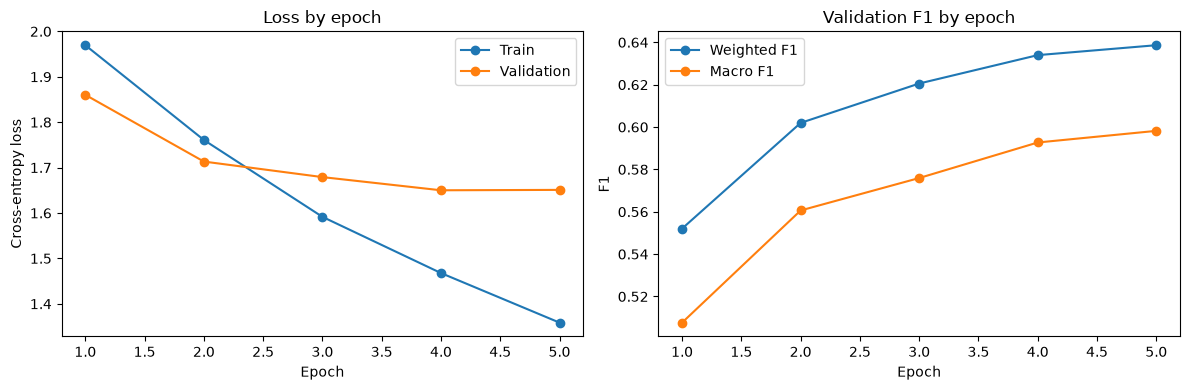

In [2]:
history_frame = pd.DataFrame(history)
display(history_frame.style.format({
    'train_loss'        : '{:.4f}',
    'validation_loss'   : '{:.4f}',
    'accuracy'          : '{:.4f}',
    'weighted_f1'       : '{:.4f}',
    'macro_f1'          : '{:.4f}',
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_frame['global_epoch'], history_frame['train_loss'], marker='o', label='Train')
axes[0].plot(history_frame['global_epoch'], history_frame['validation_loss'], marker='o', label='Validation')
axes[0].set(title='Loss by epoch', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0].legend()

axes[1].plot(history_frame['global_epoch'], history_frame['weighted_f1'], marker='o', label='Weighted F1')
axes[1].plot(history_frame['global_epoch'], history_frame['macro_f1'], marker='o', label='Macro F1')
axes[1].set(title='Validation F1 by epoch', xlabel='Epoch', ylabel='F1')
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Evaluate and save probabilities

In [5]:
best            = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(best['model_state_dict'])

final_result                = evaluate(model, validation_loader, criterion, return_probabilities=True)
prediction_frame, per_class = save_evaluation(final_result, '03_6_vit_b16')

Validation: 100%|██████████| 1062/1062 [00:45<00:00, 23.19it/s]


,validation_loss,accuracy,weighted_f1,macro_f1
vit_b16,1.6509,0.6404,0.6386,0.5982


,prdtypecode,precision,recall,f1,support
8,1281,0.326,0.343,0.334,414
6,1180,0.548,0.301,0.388,153
24,2585,0.503,0.365,0.423,499
7,1280,0.474,0.409,0.439,974
22,2582,0.438,0.459,0.449,518
2,50,0.509,0.408,0.453,336
26,2905,0.833,0.316,0.458,174
11,1302,0.470,0.512,0.490,498
17,2220,0.585,0.461,0.515,165
16,2060,0.423,0.682,0.522,999


## Interpretation

Compare ViT-B/16 with the strongest CNN on the identical validation products. Keep it only
if the gain justifies its longer runtime and memory use. A transformer trained from scratch
is not part of this experiment.